# ToysAD-8K Primary Protocol Release

**Notebook file:** `08d-toysad8k-primary-protocol-release.ipynb`

This notebook verifies the fixed 2,000-scene experiment protocol and prepares the remaining 600 development scenes for model processing. It verifies the development, calibration, and internal-lock membership hashes and confirms that their scenes and source asset groups are disjoint.

Only the remaining development RGB images are released. Calibration RGB stays sealed until Notebook 09A after the method is frozen. Internal-lock RGB stays sealed until Notebook 09C after the review policy is frozen. No held-out labels are opened in this notebook.

## Saved-output evidence copy

This notebook records the completed run for repository review. Its code and markdown match the clean runnable notebook. Private scene visuals and identifier-bearing output were removed. Safe aggregate tables and charts were retained.

Run stage: `08D Kaggle Version 2`  
Clean notebook SHA-256: `95a4916261f230a6c4d360f53dfd7618a747ae6ced25c1cf166b401ebd377a73`  
Downloaded saved-output SHA-256: `12de58c2f78c0cc587a87cac076101c50534c9b3a7152ba9fbe077912cf5e860`


## Acceptance contract

- The primary roles must contain 1,000 development, 600 calibration, and 400 internal-lock scenes.
- The 100-scene screen, 300-scene confirmation, and 600-scene remainder must reconstruct the full development role.
- There must be no scene or source asset-group overlap between primary roles.
- The released package must contain exactly 600 scenes, 20 views per scene, and 12,000 decoded RGB images.
- The model-facing package must contain opaque identifiers and RGB pixels only.
- Re-running the stage must reuse valid files and reject a checkpoint that identifies different content.
- ClearML receives only aggregate tables, figures, and hashes after computation is complete.

In [1]:
from __future__ import annotations

import json
import os
from pathlib import Path
import subprocess
import sys

sys.dont_write_bytecode = True

from IPython.display import Image as NotebookImage, display

NOTEBOOK_NAME = "08d-toysad8k-primary-protocol-release.ipynb"
EXECUTION_ENVIRONMENT = "kaggle" if Path("/kaggle/input").is_dir() else "local"
OUTPUT_ROOT = Path(os.getenv(
    "VPI_OUTPUT_ROOT",
    "/kaggle/temp/toysad8k_primary_protocol_release"
    if EXECUTION_ENVIRONMENT == "kaggle"
    else ".local/runs/toysad8k-primary-protocol-release",
)).expanduser().resolve()

In [2]:
def kaggle_dataset_roots() -> list[Path]:
    """Return bounded Kaggle mount roots without scanning the image archive."""

    input_root = Path("/kaggle/input")
    if not input_root.is_dir():
        return []
    candidates: list[Path] = []
    for pattern in (
        "*",
        "datasets/*/*",
        "datasets/*/*/versions/*",
        "notebooks/*/*",
        "notebooks/*/*/versions/*",
    ):
        candidates.extend(path for path in input_root.glob(pattern) if path.is_dir())
    return sorted(set(candidates), key=lambda path: path.as_posix())


def find_code_root() -> Path:
    configured = os.getenv("VPI_CODE_ROOT")
    candidates = [Path(configured).expanduser()] if configured else []
    candidates.extend((Path.cwd(), *Path.cwd().parents))
    for mounted in kaggle_dataset_roots():
        candidates.extend((mounted, mounted / "code"))
    for candidate in candidates:
        if (candidate / "scripts/run_primary_protocol_release.py").is_file():
            return candidate.resolve()
    mounted_names = [path.name for path in kaggle_dataset_roots()]
    raise FileNotFoundError(
        f"Could not locate the Visual Peer Inspector code snapshot. Mounted inputs: {mounted_names}"
    )


def find_directory(marker: str, variable: str) -> Path:
    """Resolve one trusted input by an exact marker and a bounded directory search."""

    configured = os.getenv(variable)
    candidates = [Path(configured).expanduser()] if configured else []
    for mounted in kaggle_dataset_roots():
        candidates.append(mounted)
        children = sorted(path for path in mounted.iterdir() if path.is_dir())
        if len(children) <= 200:
            candidates.extend(children)
    matches = []
    for candidate in candidates:
        if (candidate / marker).is_file():
            matches.append(candidate.resolve())
    unique = sorted(set(matches), key=lambda path: path.as_posix())
    if not unique:
        raise FileNotFoundError(f"Could not locate {variable} containing {marker}")
    return unique[0]


def code_environment() -> dict[str, str]:
    environment = os.environ.copy()
    source_root = str(CODE_ROOT / "src")
    previous = environment.get("PYTHONPATH")
    environment["PYTHONPATH"] = source_root if not previous else source_root + os.pathsep + previous
    return environment


def read_secret(name: str) -> str | None:
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret(name)
    except Exception:
        return os.getenv(name)


def finish_clearml(safe_root: Path, receipt: Path) -> dict:
    """Run bounded aggregate tracking after the release is already complete."""

    mode = "online" if EXECUTION_ENVIRONMENT == "kaggle" else "disabled"
    environment = code_environment()
    if mode == "online":
        access = read_secret("CLEARML_API_ACCESS_KEY")
        secret = read_secret("CLEARML_API_SECRET_KEY")
        if access and secret:
            environment.update({
                "CLEARML_API_ACCESS_KEY": access,
                "CLEARML_API_SECRET_KEY": secret,
                "CLEARML_API_HOST": "https://api.clear.ml",
                "CLEARML_WEB_HOST": "https://app.clear.ml",
                "CLEARML_FILES_HOST": "https://files.clear.ml",
            })
        else:
            mode = "disabled"
    command = [
        sys.executable,
        str(CODE_ROOT / "scripts/finalize_ds2_clearml.py"),
        "--safe-root", str(safe_root),
        "--receipt", str(receipt),
        "--stage", "primary_protocol_release",
        "--project", "Visual Peer Inspector/05 Development Freeze",
        "--task-name", "primary-protocol-release",
        "--tag", "notebook-08d",
        "--tag", "development-freeze",
        "--tag", "protocol-release",
        "--tag", "kaggle",
        "--mode", mode,
        "--wall-time-seconds", "180",
    ]
    try:
        subprocess.run(command, check=True, timeout=240, env=environment)
    except Exception as error:
        receipt.parent.mkdir(parents=True, exist_ok=True)
        receipt.write_text(json.dumps({
            "schema_version": 1,
            "stage": "primary_protocol_release_clearml_finalisation",
            "status": "failed",
            "error_type": type(error).__name__,
            "task_id": None,
        }, indent=2, sort_keys=True) + "\n", encoding="utf-8")
    return json.loads(receipt.read_text(encoding="utf-8"))

## Locate the trusted protocol and source inputs

In [3]:
CODE_ROOT = find_code_root()
sys.path.insert(0, str(CODE_ROOT / "src"))
from visual_peer_inspector.notebook_provenance import verify_notebook_code_snapshot

CODE_PROVENANCE = verify_notebook_code_snapshot(
    CODE_ROOT,
    "notebooks/development-freeze/08d-toysad8k-primary-protocol-release.ipynb",
)

SELECTION_ROOT = find_directory("experiment_roles.jsonl", "VPI_SELECTION_ROOT")
DEVELOPMENT_ROOT = find_directory("development_source_map.jsonl", "VPI_DEVELOPMENT_ROOT")
ADMINISTRATIVE_ROOT = find_directory("restricted_source_map.jsonl", "VPI_ADMINISTRATIVE_ROOT")
SOURCE_ROOT = find_directory("archive_index.sqlite3", "VPI_SOURCE_ROOT")

from visual_peer_inspector.data.cohort_contract import (
    CALIBRATION_CONTRACT,
    DEVELOPMENT_REMAINDER_CONTRACT,
    INTERNAL_LOCK_CONTRACT,
)

display({
    "environment": EXECUTION_ENVIRONMENT,
    "release": DEVELOPMENT_REMAINDER_CONTRACT.release_id,
    "development remainder scenes": DEVELOPMENT_REMAINDER_CONTRACT.scene_count,
    "development remainder images": DEVELOPMENT_REMAINDER_CONTRACT.image_count,
    "calibration scenes verified but sealed": CALIBRATION_CONTRACT.scene_count,
    "internal-lock scenes verified but sealed": INTERNAL_LOCK_CONTRACT.scene_count,
})

{'environment': 'kaggle',
 'release': 'toysad8k-train-2000-v2',
 'development remainder scenes': 600,
 'development remainder images': 12000,
 'calibration scenes verified but sealed': 600,
 'internal-lock scenes verified but sealed': 400}

## Verify the protocol and build the development release

In [4]:
# The package builder validates existing files before reusing them, so an interrupted
# run can restart without copying valid images again.
command = [
    sys.executable,
    str(CODE_ROOT / "scripts/run_primary_protocol_release.py"),
    "--selection-root", str(SELECTION_ROOT),
    "--development-root", str(DEVELOPMENT_ROOT),
    "--administrative-root", str(ADMINISTRATIVE_ROOT),
    "--source-root", str(SOURCE_ROOT),
    "--output-root", str(OUTPUT_ROOT),
]
if EXECUTION_ENVIRONMENT == "kaggle":
    # Kaggle mounts are immutable and already identified by their dataset version.
    command.append("--skip-archive-byte-check")

subprocess.run(command, check=True, env=code_environment())
SAFE_ROOT = OUTPUT_ROOT / "safe"
run_record = json.loads((SAFE_ROOT / "run_record.json").read_text(encoding="utf-8"))
display({
    "status": run_record["status"],
    "primary scenes verified": run_record["primary_scene_count"],
    "released development scenes": run_record["released_scene_count"],
    "released RGB images": run_record["released_image_count"],
    "images written this run": run_record["files_written_this_run"],
    "images reused this run": run_record["files_reused_this_run"],
    "held-out scenes in model package": run_record["model_package_contains_held_out_scenes"],
})

{
  "all_completion_gates_passed": true,
  "calibration_labels_opened": false,
  "calibration_media_released": false,
  "calibration_scene_count": 600,
  "checkpoint_sha256": "66c89b295a7ed474b206c7ec8a5905b5a02ff93b33b0a0484e97e59a6c524a06",
  "development_scene_count": 1000,
  "files_reused_this_run": 0,
  "files_written_this_run": 12000,
  "internal_lock_labels_opened": false,
  "internal_lock_media_released": false,
  "internal_lock_scene_count": 400,
  "model_package_contains_held_out_scenes": false,
  "primary_scene_count": 2000,
  "release_id": "toysad8k-train-2000-v2",
  "released_asset_group_count": 164,
  "released_content_checksums_sha256": "22080f1591b1c8e0a8951548826af76bf51755f1cc04c78d3b4dfb68a0cedc65",
  "released_image_count": 12000,
  "released_manifest_sha256": "59506fc22cdad0606c25af770ef51853d965468b99a8e09d2e0cfaa17313a352",
  "released_membership_sha256": "e6b4e91dd99de72ddad6e462948c5a4c87b8594be230b3ed7950af841d0a2198",
  "released_scene_count": 600,
  "schema_

{'status': 'completed',
 'primary scenes verified': 2000,
 'released development scenes': 600,
 'released RGB images': 12000,
 'images written this run': 12000,
 'images reused this run': 0,
 'held-out scenes in model package': False}

## Membership, separation, and release evidence

,cohort,role,scenes,views,asset_groups,membership_sha256,membership_verified,rgb_release
0,toysad8k-development-full-1000-v1,development,1000,20000,273,00e400350a056631778bd9c4dace1667d95e52bf58c0a2...,True,complete_across_development_stages
1,toysad8k-calibration-600-v1,calibration,600,12000,163,6700bb065210bfd45188babd2b3d45973d6b4f57e5066d...,True,sealed
2,toysad8k-internal-lock-400-v1,internal_lock,400,8000,109,819f21f49705f9398c809002905abe52b8305ad41e4cab...,True,sealed


,cohort,stage,scenes,views,asset_groups,membership_sha256,membership_verified
0,toysad8k-development-screen-100-v1,screen_100,100,2000,27,308e2e104448612dc60b5392a5258d97f6d93f52ca553a...,True
1,toysad8k-development-confirm-300-v1,confirm_300,300,6000,82,bc00e95781a6d52c25c9e40364f8dfa36ad7874cccd759...,True
2,toysad8k-development-remainder-600-v1,remainder_600,600,12000,164,e6b4e91dd99de72ddad6e462948c5a4c87b8594be230b3...,True


,left_role,right_role,scene_overlap,asset_group_overlap,passed
0,development,calibration,0,0,True
1,development,internal_lock,0,0,True
2,calibration,internal_lock,0,0,True


,role,scene_count,image_count,media_state,label_state,next_notebook
0,development_remaining,600,12000,released,not_in_model_package,08E
1,calibration,600,12000,sealed,sealed,09A_after_method_freeze
2,internal_lock,400,8000,sealed,sealed,09C_after_policy_freeze


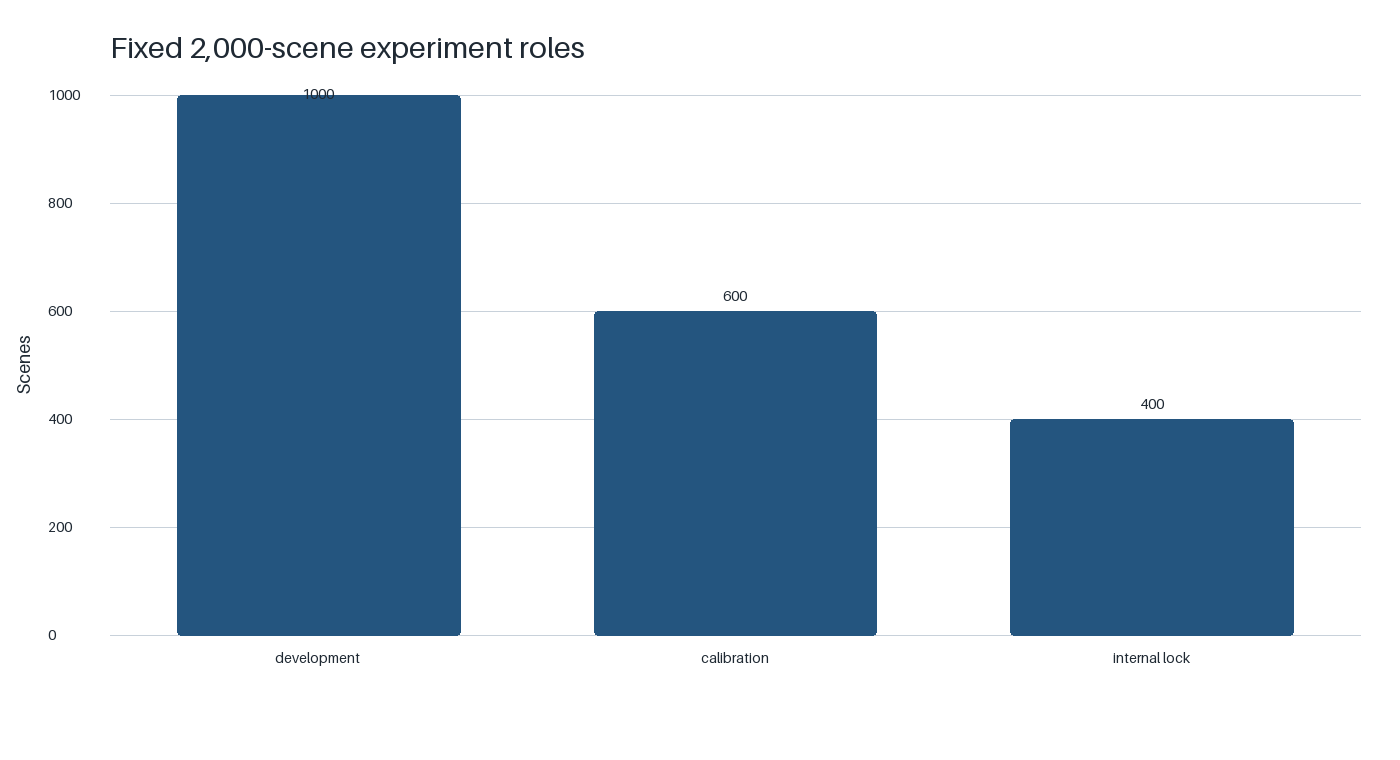

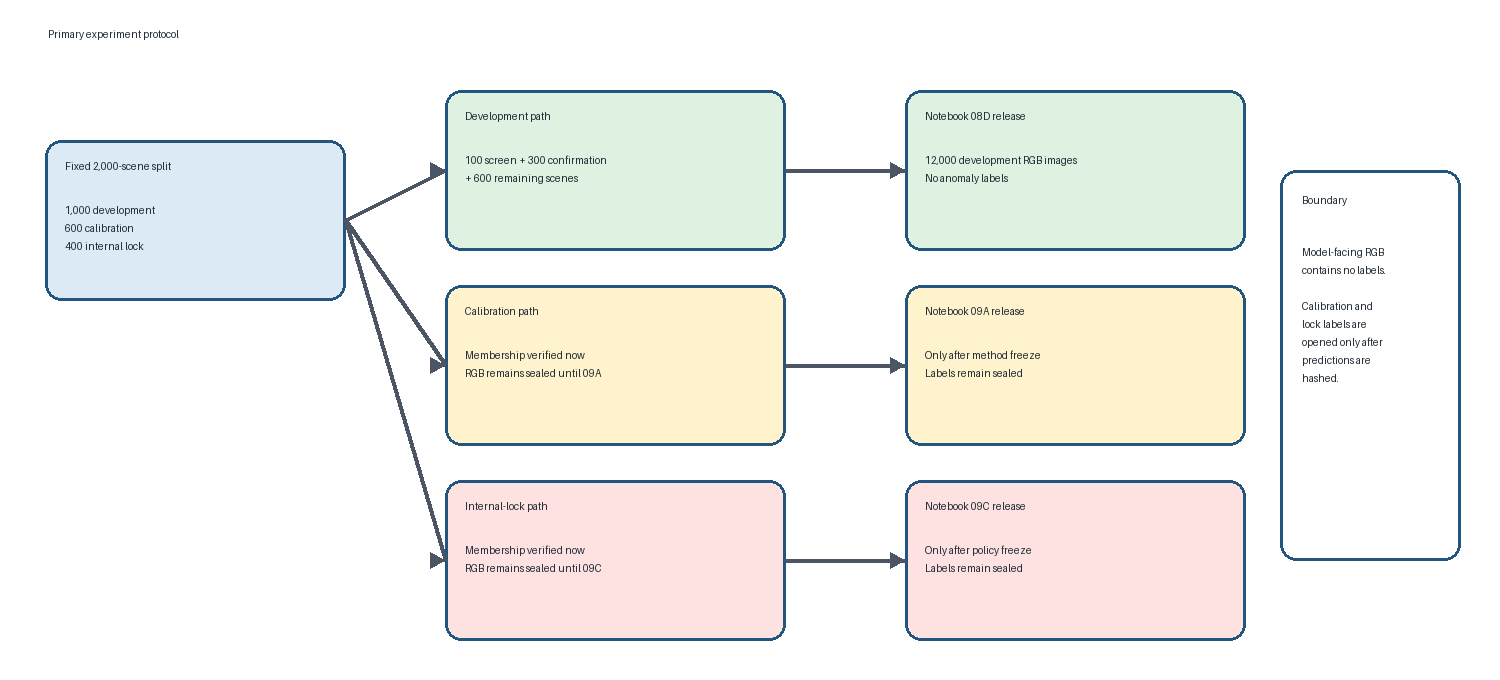

In [5]:
import pandas as pd

membership = pd.read_csv(SAFE_ROOT / "cohort_membership.csv")
development_stages = pd.read_csv(SAFE_ROOT / "development_stage_membership.csv")
overlap = pd.read_csv(SAFE_ROOT / "role_overlap_audit.csv")
release_status = pd.read_csv(SAFE_ROOT / "resource_release_status.csv")
display(membership)
display(development_stages)
display(overlap)
display(release_status)
display(NotebookImage(filename=str(SAFE_ROOT / "primary_role_counts.png")))
display(NotebookImage(filename=str(SAFE_ROOT / "protocol_release_boundary.png")))

if not run_record["all_completion_gates_passed"] or not overlap["passed"].all():
    raise RuntimeError("Primary protocol release acceptance failed")

## Development-only qualitative check

In [6]:
# This contact sheet contains only opaque development scenes. It is kept in the
# review archive and is not included in aggregate evidence or ClearML.
contact_sheet = OUTPUT_ROOT / "private/figures/development_rgb_contact_sheet.png"
display(NotebookImage(filename=str(contact_sheet)))

<IPython.core.display.Image object>

## Bounded ClearML finalisation

Tracking starts only after all release checks, tables, figures, run records, and hashes are complete. The separate tracking process can time out or fail without stopping the completed data release. Only the `safe` aggregate folder is provided to ClearML.

In [7]:
if EXECUTION_ENVIRONMENT == "kaggle":
    try:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", "-r", str(CODE_ROOT / "requirements/confirmation-tracking-lock.txt")],
            check=True,
            timeout=180,
        )
    except Exception as error:
        print(f"ClearML dependency setup was unavailable: {type(error).__name__}")

tracking_receipt = finish_clearml(SAFE_ROOT, OUTPUT_ROOT / "clearml_receipt.json")
display(tracking_receipt)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 18.4 MB/s eta 0:00:00


{'git_commit': 'bf6a576bbaca479c71ee7c58f636089e0997b39e',
 'git_dirty': False,
 'mode': 'disabled',
 'notebook_sha256': '95a4916261f230a6c4d360f53dfd7618a747ae6ced25c1cf166b401ebd377a73',
 'run_status': 'completed',
 'safe_manifest_sha256': '805098125612d14d0d7490724124bdbbe50e8cbf3f6950ff7a215c9615ff5e58',
 'schema_version': 1,
 'snapshot_sha256': '5d37b3d0d81bebeb5497234c9755a5501eb23314f117e092115629e26f59126e',
 'stage': 'primary_protocol_release_clearml_finalisation',
 'status': 'disabled',
 'task_id': None,
 'tracking_attempt_count': 0,
 'tracking_retry_count': 0,
 'tracking_transient_failure_count': 0}

## Build verified outputs

The repository archive contains aggregate audit evidence. The review archive contains the development-only contact sheet and tracking receipt. The downstream archive contains the complete 600-scene RGB package and its release checkpoint for Notebook 08E. Calibration and internal-lock media are not included in any output.

In [8]:
BUNDLE_ROOT = (
    Path("/kaggle/working/notebook08d_bundles")
    if EXECUTION_ENVIRONMENT == "kaggle"
    else OUTPUT_ROOT.parent / "notebook08d_bundles"
)
verification_path = BUNDLE_ROOT / "primary-protocol-release-verification.json"
if not verification_path.is_file():
    subprocess.run(
        [
            sys.executable,
            str(CODE_ROOT / "scripts/package_kaggle_stage_output.py"),
            "--stage-root", str(OUTPUT_ROOT),
            "--output-root", str(BUNDLE_ROOT),
            "--stage-name", "primary-protocol-release",
            "--review-path", "private/figures",
            "--review-path", "clearml_receipt.json",
            "--downstream-path", "development-remainder/model-input",
            "--downstream-path", "release_checkpoint.json",
        ],
        check=True,
        env=code_environment(),
    )

bundle_record = json.loads(verification_path.read_text(encoding="utf-8"))
display(pd.DataFrame(bundle_record["archives"]))
print(f"Verified downloads: {BUNDLE_ROOT}")

{"archives": [{"path": "primary-protocol-release-repository-evidence.zip", "sha256": "77e3150047e7e4f4d9fd8a34d1cb0e5b3f87a90225e9c6e3c9b3dc4279b48c4e", "size_bytes": 54777, "source_file_count": 8}, {"path": "primary-protocol-release-review-evidence.zip", "sha256": "320d5fb47aabef31ccc2121aabefa86d495d02bb3fad8ddda647b5632bdc6b64", "size_bytes": 901146, "source_file_count": 2}, {"path": "primary-protocol-release-downstream-input.zip", "sha256": "49e957e534c9baa8957a912b0f1e54037b1f4417181eb4e5c66723e54c89643f", "size_bytes": 1524655144, "source_file_count": 12004}], "downstream_file_count": 12004, "review_file_count": 2, "safe_file_count": 8, "safe_manifest_sha256": "805098125612d14d0d7490724124bdbbe50e8cbf3f6950ff7a215c9615ff5e58", "schema_version": 1, "stage": "primary-protocol-release", "status": "completed"}


,path,sha256,size_bytes,source_file_count
0,primary-protocol-release-repository-evidence.zip,77e3150047e7e4f4d9fd8a34d1cb0e5b3f87a90225e9c6...,54777,8
1,primary-protocol-release-review-evidence.zip,320d5fb47aabef31ccc2121aabefa86d495d02bb3fad8d...,901146,2
2,primary-protocol-release-downstream-input.zip,49e957e534c9baa8957a912b0f1e54037b1f4417181eb4...,1524655144,12004


Verified downloads: /kaggle/working/notebook08d_bundles


## Next stage

Publish the verified downstream archive as a private derived Kaggle dataset for Notebook 08E. Notebook 08E runs the frozen LocateAnything, SAM 2.1 Hiera-large, and DINOv2-small P1 pipeline on the remaining 600 development scenes. It must not attach calibration or internal-lock media. Calibration is released only after the full method, cross-view association, and review policy have been fixed.